# Part B — Mobility and Infection-Avoidance Behavior

This notebook extends the Part A SIR agent-based model to compare:

- **Stay probability $m$:** $0.10$, $0.30$, $0.60$, and $1.00$. Here, $m$ is explicitly the probability of **not moving**. Therefore, an agent attempts a cardinal move with probability $1-m$.
- **Avoidance:** off versus on. With avoidance on, an intended move is rejected when its destination cell contained at least one infected agent immediately before movement.

The experiment reports peak infection strength and peak timing across repeated runs, then uses spatial snapshots to show why mobility and avoidance change the epidemic.

In [1]:
from dataclasses import dataclass, asdict
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.style.use("seaborn-v0_8-whitegrid")

SUSCEPTIBLE, INFECTED, RECOVERED = 0, 1, 2
STATE_NAMES = np.array(["Susceptible", "Infected", "Recovered"])
STATE_COLORS = {
    SUSCEPTIBLE: "#3B82F6",
    INFECTED: "#EF4444",
    RECOVERED: "#10B981",
}
AVOIDANCE_COLORS = {False: "#F97316", True: "#2563EB"}
AVOIDANCE_LABELS = {False: "Without avoidance", True: "With avoidance"}


## 1. Experiment configuration

Edit this cell to change population, disease, replication, or snapshot settings. The disease parameters match the default Part A model. Thirty runs per scenario exceed the minimum of 20 and produce more stable estimates.

In [2]:
@dataclass(frozen=True)
class ExperimentConfig:
    grid_size: int = 20
    initial_susceptible: int = 195
    initial_infected: int = 5
    initial_recovered: int = 0
    transmission_probability: float = 0.35
    recovery_probability: float = 0.03
    time_steps: int = 300
    n_runs: int = 30
    seed: int = 501
    stay_probabilities: tuple = (0.10, 0.30, 0.60, 1.00)
    snapshot_stay_probabilities: tuple = (0.10, 0.60)
    snapshot_times: tuple = (0, 50, 100, 150, 300)

CONFIG = ExperimentConfig()

def validate_config(config):
    counts = (config.initial_susceptible, config.initial_infected,
              config.initial_recovered)
    if config.grid_size < 1 or min(counts) < 0 or sum(counts) < 1:
        raise ValueError("Use a positive grid and valid nonnegative state counts.")
    probabilities = (config.transmission_probability, config.recovery_probability,
                     *config.stay_probabilities)
    if any(not 0 <= value <= 1 for value in probabilities):
        raise ValueError("All probabilities must lie between 0 and 1.")
    if config.n_runs < 1 or config.time_steps < 0:
        raise ValueError("n_runs must be positive and time_steps nonnegative.")
    if any(t < 0 or t > config.time_steps for t in config.snapshot_times):
        raise ValueError("Snapshot times must fall within the simulation horizon.")
    if not set(config.snapshot_stay_probabilities).issubset(config.stay_probabilities):
        raise ValueError("Snapshot mobility values must be included in the experiment.")
    return sum(counts)

N_AGENTS = validate_config(CONFIG)
pd.Series(asdict(CONFIG), name="value").to_frame().rename_axis("parameter")


,value
parameter,
grid_size,20
initial_susceptible,195
initial_infected,5
initial_recovered,0
transmission_probability,0.35
recovery_probability,0.03
time_steps,300
n_runs,30
seed,501


## 2. Model with optional avoidance

At each time step, the model uses this synchronous schedule:

1. Record which cells currently contain infected agents—this is the information used for avoidance.
2. Every agent stays with probability $m$; otherwise it proposes one uniformly random cardinal move.
3. Reject moves that cross the boundary. If avoidance is on, also reject proposed moves whose destination was infected in step 1.
4. Move all accepted agents simultaneously, then apply transmission and recovery as in Part A.

Avoidance applies to every agent and considers only the proposed **destination**. Infected agents can still move into uninfected cells, so avoidance reduces risky approaches but cannot prevent all exposure.

In [3]:
def initialize_population(config, rng):
    positions = rng.integers(0, config.grid_size, size=(N_AGENTS, 2))
    states = np.concatenate([
        np.full(config.initial_susceptible, SUSCEPTIBLE, dtype=np.int8),
        np.full(config.initial_infected, INFECTED, dtype=np.int8),
        np.full(config.initial_recovered, RECOVERED, dtype=np.int8),
    ])
    rng.shuffle(states)
    return positions, states


def move_agents(positions, states, stay_probability, avoidance, config, rng):
    """Apply one bounded move, optionally avoiding previously infected destinations."""
    directions = np.array([[-1, 0], [1, 0], [0, -1], [0, 1]], dtype=int)
    intends_to_move = rng.random(len(positions)) >= stay_probability
    proposed = positions.copy()
    proposed[intends_to_move] += directions[
        rng.integers(0, 4, size=intends_to_move.sum())
    ]

    accepted = intends_to_move & ((proposed >= 0) & (proposed < config.grid_size)).all(axis=1)

    if avoidance:
        infected_cells = np.zeros((config.grid_size, config.grid_size), dtype=bool)
        infected_positions = positions[states == INFECTED]
        if len(infected_positions):
            infected_cells[infected_positions[:, 0], infected_positions[:, 1]] = True

        valid_indices = np.flatnonzero(accepted)
        risky_destination = infected_cells[
            proposed[valid_indices, 0], proposed[valid_indices, 1]
        ]
        accepted[valid_indices[risky_destination]] = False

    positions[accepted] = proposed[accepted]


def update_health_states(positions, states, config, rng):
    infected_before_update = states == INFECTED
    infected_by_cell = np.zeros((config.grid_size, config.grid_size), dtype=int)
    infected_positions = positions[infected_before_update]
    if len(infected_positions):
        np.add.at(infected_by_cell,
                  (infected_positions[:, 0], infected_positions[:, 1]), 1)

    exposed = ((states == SUSCEPTIBLE)
               & (infected_by_cell[positions[:, 0], positions[:, 1]] > 0))
    newly_infected = exposed & (rng.random(len(states)) < config.transmission_probability)
    recovered_now = (infected_before_update
                     & (rng.random(len(states)) < config.recovery_probability))
    states[newly_infected] = INFECTED
    states[recovered_now] = RECOVERED


def state_counts(states):
    return np.bincount(states, minlength=3)


def simulate(config, stay_probability, avoidance, rng, keep_snapshots=False):
    positions, states = initialize_population(config, rng)
    history = np.empty((config.time_steps + 1, 3), dtype=int)
    history[0] = state_counts(states)

    requested = set(config.snapshot_times) if keep_snapshots else set()
    snapshots = {}
    if 0 in requested:
        snapshots[0] = (positions.copy(), states.copy())

    for step in range(1, config.time_steps + 1):
        move_agents(positions, states, stay_probability, avoidance, config, rng)
        update_health_states(positions, states, config, rng)
        history[step] = state_counts(states)
        if step in requested:
            snapshots[step] = (positions.copy(), states.copy())

    return history, snapshots


## 3. Factorial experiment

The same set of run seeds is replayed for every scenario. This common-random-number design gives each mobility/avoidance condition the same initial populations and underlying random draws, reducing irrelevant Monte Carlo noise in head-to-head comparisons. Spatial snapshots are retained from the first run of each scenario.

In [4]:
run_seeds = np.random.SeedSequence(CONFIG.seed).spawn(CONFIG.n_runs)
scenario_histories = {}
scenario_snapshots = {}
metric_rows = []

start = perf_counter()
for stay_probability in CONFIG.stay_probabilities:
    for avoidance in (False, True):
        histories = np.empty((CONFIG.n_runs, CONFIG.time_steps + 1, 3), dtype=int)
        for run_id, run_seed in enumerate(run_seeds):
            history, snapshots = simulate(
                CONFIG, stay_probability, avoidance,
                np.random.default_rng(run_seed), keep_snapshots=(run_id == 0)
            )
            histories[run_id] = history
            infected = history[:, INFECTED]
            metric_rows.append({
                "stay_probability": stay_probability,
                "avoidance": avoidance,
                "run": run_id + 1,
                "peak_infected": infected.max(),
                "time_to_peak": infected.argmax(),
            })
            if run_id == 0:
                scenario_snapshots[(stay_probability, avoidance)] = snapshots
        scenario_histories[(stay_probability, avoidance)] = histories

metrics = pd.DataFrame(metric_rows)
assert np.all([
    np.all(histories.sum(axis=2) == N_AGENTS)
    for histories in scenario_histories.values()
])
elapsed = perf_counter() - start
print(
    f"Completed {len(CONFIG.stay_probabilities) * 2} scenarios × "
    f"{CONFIG.n_runs} runs × {CONFIG.time_steps} steps in {elapsed:.2f} seconds."
)
print("Population-conservation checks passed.")


Completed 8 scenarios × 30 runs × 300 steps in 2.85 seconds.
Population-conservation checks passed.


## 4. Peak strength and time-to-peak comparison

Lines connect scenario averages. Error bars are 95% confidence intervals for the mean across runs, and faint points show individual runs. Because `m` is the stay probability, movement decreases from left to right.

In [5]:
summary = (
    metrics.groupby(["stay_probability", "avoidance"], as_index=False)
    .agg(
        n=("run", "count"),
        mean_peak_infected=("peak_infected", "mean"),
        sd_peak_infected=("peak_infected", "std"),
        mean_time_to_peak=("time_to_peak", "mean"),
        sd_time_to_peak=("time_to_peak", "std"),
    )
)
summary["ci_peak_infected"] = 1.96 * summary["sd_peak_infected"] / np.sqrt(summary["n"])
summary["ci_time_to_peak"] = 1.96 * summary["sd_time_to_peak"] / np.sqrt(summary["n"])

display(
    summary.assign(avoidance=summary["avoidance"].map(AVOIDANCE_LABELS))
    .round(2)
    .style.hide(axis="index")
)


stay_probability,avoidance,n,mean_peak_infected,sd_peak_infected,mean_time_to_peak,sd_time_to_peak,ci_peak_infected,ci_time_to_peak
0.100000,Without avoidance,30,71.170000,10.410000,66.730000,15.680000,3.730000,5.610000
0.100000,With avoidance,30,75.870000,12.300000,59.670000,16.360000,4.400000,5.850000
0.300000,Without avoidance,30,68.500000,12.740000,62.870000,17.660000,4.560000,6.320000
0.300000,With avoidance,30,62.600000,13.340000,72.770000,23.850000,4.770000,8.540000
0.600000,Without avoidance,30,48.170000,11.650000,85.830000,33.650000,4.170000,12.040000
0.600000,With avoidance,30,37.870000,9.750000,110.600000,49.650000,3.490000,17.770000
1.000000,Without avoidance,30,7.230000,1.520000,2.500000,1.740000,0.550000,0.620000
1.000000,With avoidance,30,7.230000,1.520000,2.500000,1.740000,0.550000,0.620000


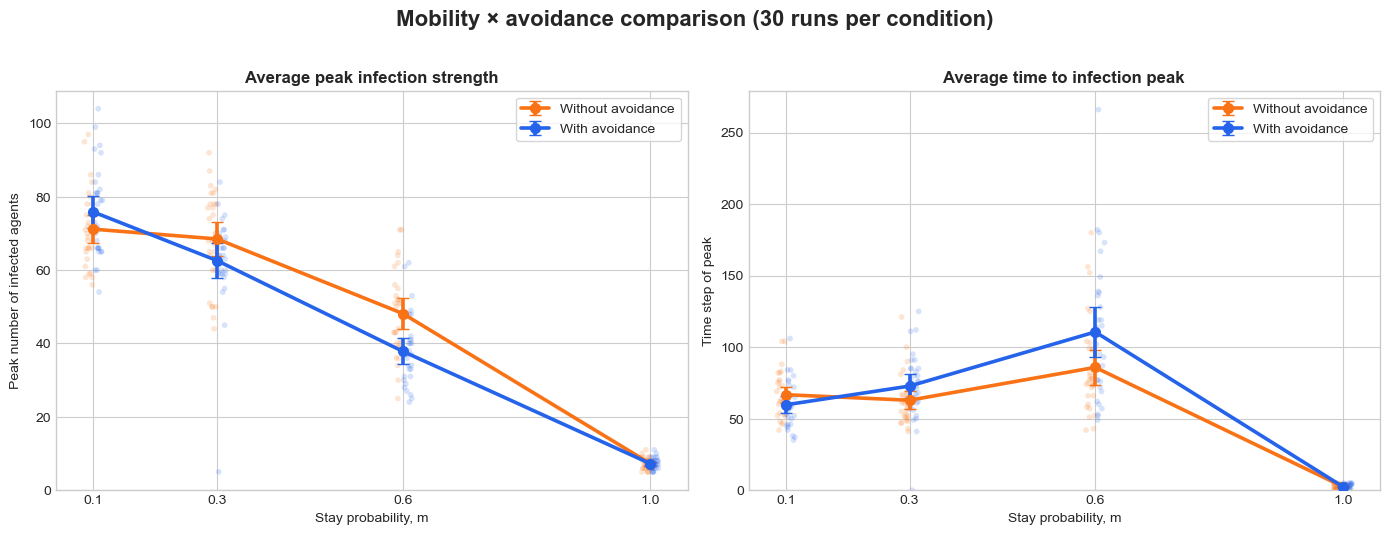

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
plot_rng = np.random.default_rng(CONFIG.seed + 1_000)
metric_specs = [
    ("peak_infected", "mean_peak_infected", "ci_peak_infected",
     "Average peak infection strength", "Peak number of infected agents"),
    ("time_to_peak", "mean_time_to_peak", "ci_time_to_peak",
     "Average time to infection peak", "Time step of peak"),
]

for ax, (raw_col, mean_col, ci_col, title, ylabel) in zip(axes, metric_specs):
    for avoidance in (False, True):
        raw = metrics[metrics["avoidance"] == avoidance]
        grouped = summary[summary["avoidance"] == avoidance].sort_values("stay_probability")
        offset = -0.008 if not avoidance else 0.008
        x_jitter = (raw["stay_probability"].to_numpy() + offset
                    + plot_rng.uniform(-0.007, 0.007, size=len(raw)))
        ax.scatter(x_jitter, raw[raw_col], color=AVOIDANCE_COLORS[avoidance],
                   s=17, alpha=0.18, edgecolors="none")
        ax.errorbar(
            grouped["stay_probability"], grouped[mean_col], yerr=grouped[ci_col],
            color=AVOIDANCE_COLORS[avoidance], marker="o", markersize=7, lw=2.6,
            capsize=4, label=AVOIDANCE_LABELS[avoidance], zorder=4
        )

    ax.set_title(title, weight="bold")
    ax.set_xlabel("Stay probability, m")
    ax.set_ylabel(ylabel)
    ax.set_xticks(CONFIG.stay_probabilities)
    ax.set_xlim(0.04, 1.06)
    ax.set_ylim(bottom=0)
    ax.legend(frameon=True)

fig.suptitle(
    f"Mobility × avoidance comparison ({CONFIG.n_runs} runs per condition)",
    fontsize=16, weight="bold", y=1.02
)
fig.tight_layout()
plt.show()


### Matched effect of avoidance

The following table subtracts each no-avoidance result from the matched avoidance result using the same run seed. Negative peak differences mean that avoidance reduced the maximum infected population; positive timing differences mean that avoidance delayed the peak.

In [7]:
paired = metrics.pivot(
    index=["stay_probability", "run"], columns="avoidance",
    values=["peak_infected", "time_to_peak"]
)
paired_effects = pd.DataFrame({
    "stay_probability": paired.index.get_level_values("stay_probability"),
    "run": paired.index.get_level_values("run"),
    "peak_change_with_avoidance": (
        paired[("peak_infected", True)] - paired[("peak_infected", False)]
    ).to_numpy(),
    "peak_time_change_with_avoidance": (
        paired[("time_to_peak", True)] - paired[("time_to_peak", False)]
    ).to_numpy(),
})

effect_report = (
    paired_effects.groupby("stay_probability", as_index=False)
    .agg(
        mean_peak_change=("peak_change_with_avoidance", "mean"),
        median_peak_change=("peak_change_with_avoidance", "median"),
        mean_peak_time_change=("peak_time_change_with_avoidance", "mean"),
        median_peak_time_change=("peak_time_change_with_avoidance", "median"),
    )
    .round(2)
)
display(effect_report.style.hide(axis="index"))


stay_probability,mean_peak_change,median_peak_change,mean_peak_time_change,median_peak_time_change
0.100000,4.700000,6.000000,-7.070000,-4.000000
0.300000,-5.900000,-6.000000,9.900000,11.500000
0.600000,-10.300000,-10.000000,24.770000,19.000000
1.000000,0.000000,0.000000,0.000000,0.000000


## 5. Spatial snapshots for intuitive comparison

The panels below compare matched first runs at high movement (`m=0.10`) and moderate movement (`m=0.60`), with and without avoidance. Rows within each mobility pair begin from the same random initial population. Small plotting-only jitter makes agents sharing a cell visible; it does not change the simulation.

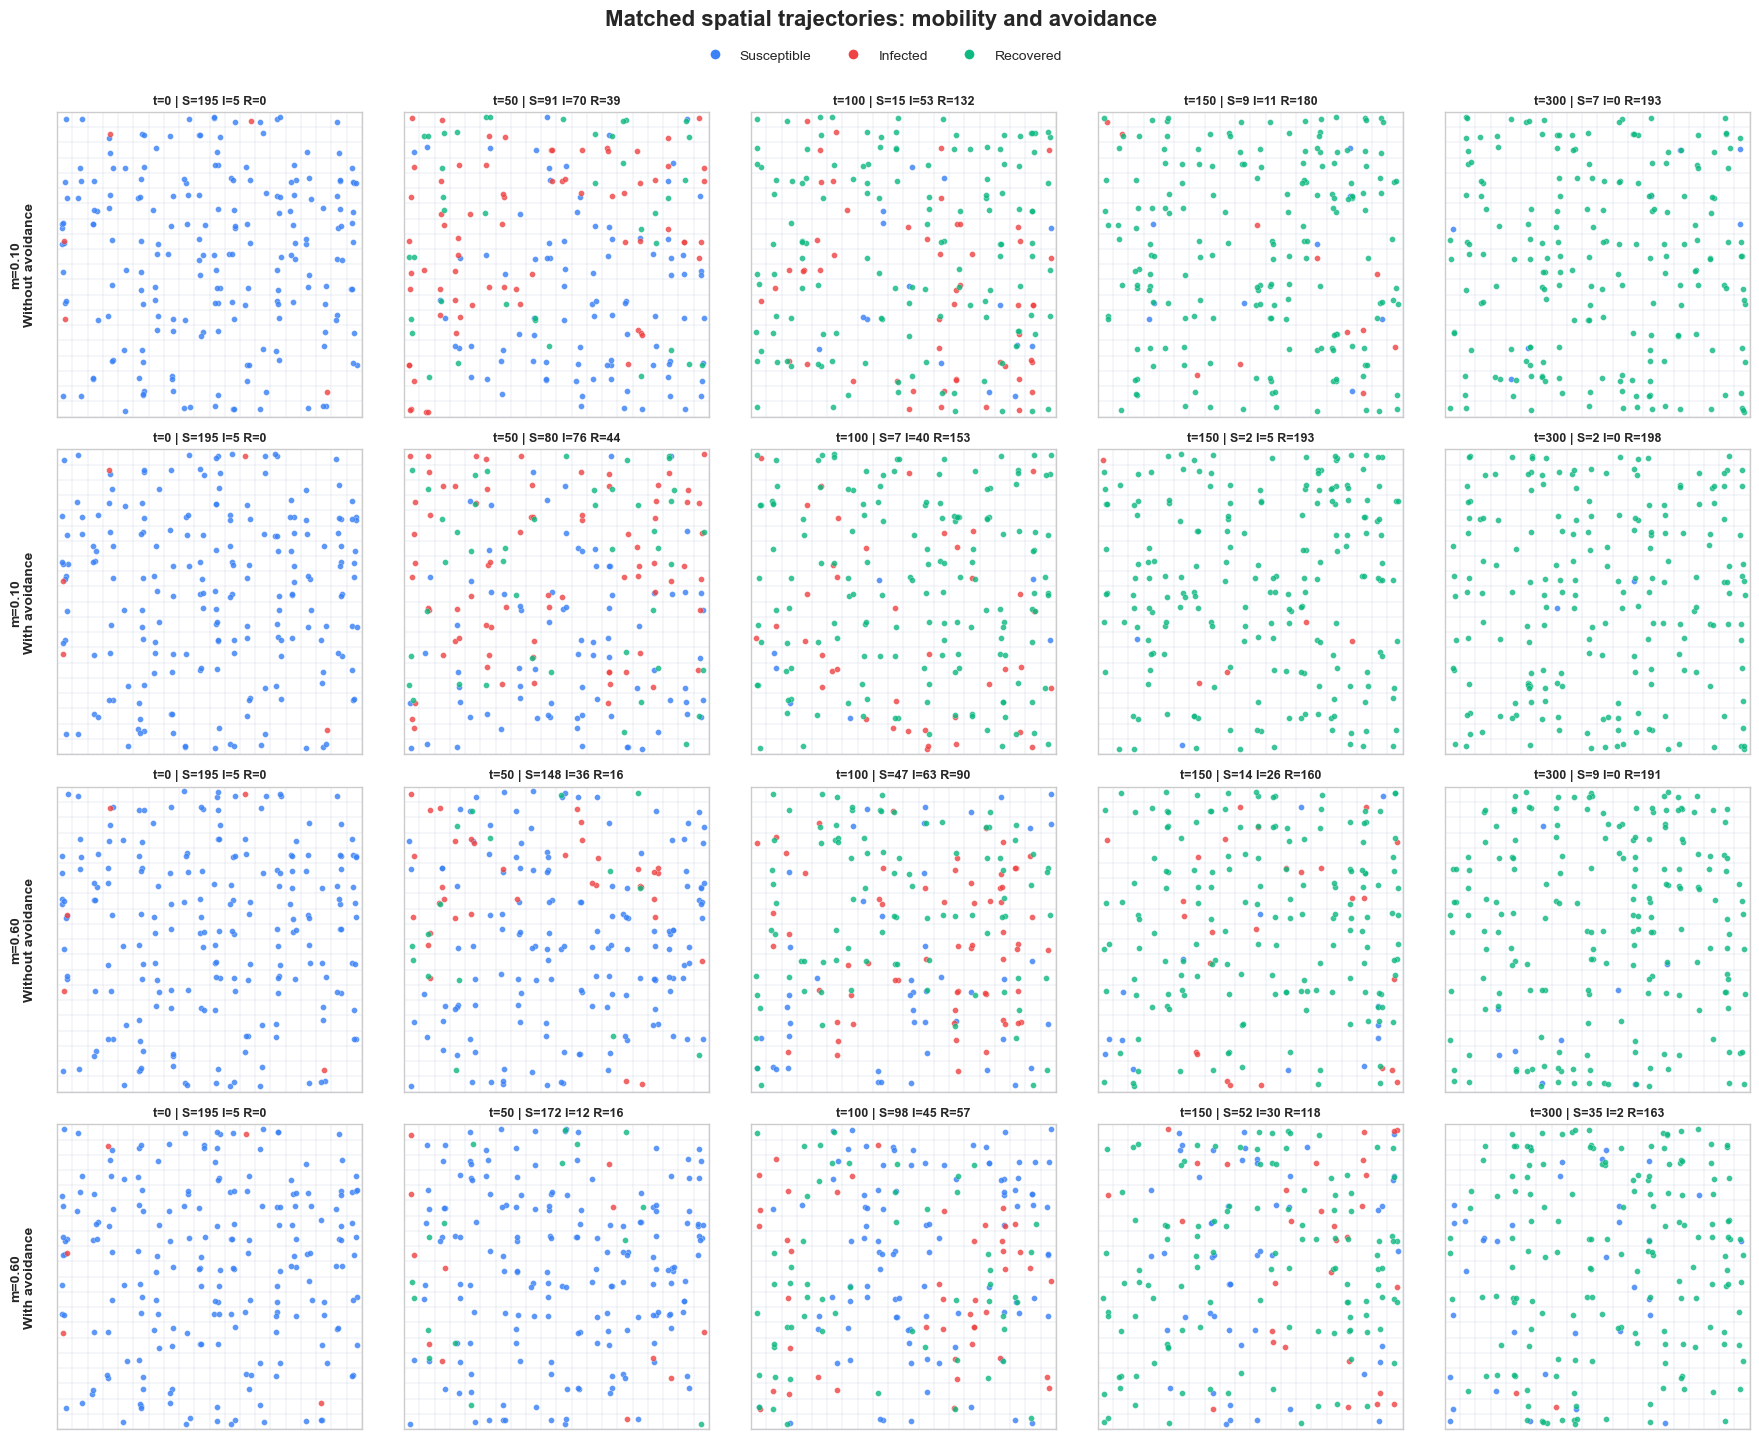

In [8]:
snapshot_rows = [
    (stay_probability, avoidance)
    for stay_probability in CONFIG.snapshot_stay_probabilities
    for avoidance in (False, True)
]
snapshot_times = sorted(CONFIG.snapshot_times)
fig, axes = plt.subplots(
    len(snapshot_rows), len(snapshot_times),
    figsize=(3.6 * len(snapshot_times), 3.5 * len(snapshot_rows)), squeeze=False
)
snapshot_plot_rng = np.random.default_rng(CONFIG.seed + 2_000)

for row, (stay_probability, avoidance) in enumerate(snapshot_rows):
    snapshots = scenario_snapshots[(stay_probability, avoidance)]
    for col, step in enumerate(snapshot_times):
        ax = axes[row, col]
        positions, states = snapshots[step]
        jitter = snapshot_plot_rng.uniform(-0.20, 0.20, size=positions.shape)

        for state in (SUSCEPTIBLE, INFECTED, RECOVERED):
            mask = states == state
            ax.scatter(
                positions[mask, 1] + jitter[mask, 1],
                positions[mask, 0] + jitter[mask, 0],
                s=18, color=STATE_COLORS[state], alpha=0.82,
                edgecolors="white", linewidths=0.2
            )

        counts = state_counts(states)
        ax.set_title(f"t={step} | S={counts[0]} I={counts[1]} R={counts[2]}",
                     fontsize=9, weight="bold")
        ax.set_xlim(-0.5, CONFIG.grid_size - 0.5)
        ax.set_ylim(CONFIG.grid_size - 0.5, -0.5)
        ax.set_aspect("equal")
        ax.set_xticks(np.arange(-0.5, CONFIG.grid_size, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, CONFIG.grid_size, 1), minor=True)
        ax.grid(which="minor", color="#CBD5E1", linewidth=0.28)
        ax.grid(which="major", visible=False)
        ax.set_xticks([])
        ax.set_yticks([])

        if col == 0:
            ax.set_ylabel(
                f"m={stay_probability:.2f}\n{AVOIDANCE_LABELS[avoidance]}",
                fontsize=10, weight="bold", labelpad=12
            )

legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=STATE_COLORS[state],
           markeredgecolor="white", markersize=8, label=STATE_NAMES[state])
    for state in (SUSCEPTIBLE, INFECTED, RECOVERED)
]
fig.legend(handles=legend_handles, loc="upper center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.005))
fig.suptitle("Matched spatial trajectories: mobility and avoidance",
             fontsize=16, weight="bold", y=1.025)
fig.tight_layout()
plt.show()


## 6. Interpretation guide

- Moving agents mix the population across cells. Therefore, smaller $m$ generally creates more opportunities for susceptible and infected agents to meet, while larger $m$ preserves local separation.
- Avoidance removes one class of risky contacts: an agent does not voluntarily enter a cell known to contain infection at the start of that step. This can lower or delay the peak.
- Avoidance is not perfect protection. Its information is one movement phase old, infected agents may move into susceptible agents' cells, and susceptible agents already sharing a cell with infection do not escape automatically.
- At $m=1$, nobody proposes a move, so the avoidance rule has nothing to reject. The paired scenarios should consequently be identical; this is a useful implementation check.

Use the mean curves for the overall comparison, the faint points and confidence intervals for stochastic variability, and the matched snapshots for a spatial explanation of the observed differences.

## 7. Head-to-head comparison with strict quarantine at $m=0.10$

This section fixes the baseline stay probability at $m=0.10$ and compares three policies:

1. **No avoidance:** ordinary movement with a 0.10 chance to stay.
2. **Avoidance only:** the destination-avoidance rule from the preceding experiment.
3. **Strict quarantine:** avoidance remains active, while every infected agent and every susceptible agent currently sharing a cell with infection has a 0.90 chance to stay. All other agents retain $m=0.10$.

Quarantine status is recalculated immediately before each movement phase using the current positions and health states. Recovered agents are not quarantined.

In [9]:
FIXED_M = 0.10
QUARANTINE_STAY_PROBABILITY = 0.90

POLICY_COLORS = {
    "No avoidance": "#F97316",
    "Avoidance only": "#2563EB",
    "Strict quarantine": "#7C3AED",
}


def move_agents_with_strict_quarantine(
    positions, states, baseline_stay_probability, quarantine_stay_probability,
    config, rng
):
    """Apply avoidance plus elevated stay probability for quarantined agents."""
    infected_cells = np.zeros((config.grid_size, config.grid_size), dtype=bool)
    infected_positions = positions[states == INFECTED]
    if len(infected_positions):
        infected_cells[infected_positions[:, 0], infected_positions[:, 1]] = True

    susceptible_with_infection = (
        (states == SUSCEPTIBLE)
        & infected_cells[positions[:, 0], positions[:, 1]]
    )
    quarantined = (states == INFECTED) | susceptible_with_infection
    effective_stay_probability = np.where(
        quarantined, quarantine_stay_probability, baseline_stay_probability
    )

    directions = np.array([[-1, 0], [1, 0], [0, -1], [0, 1]], dtype=int)
    intends_to_move = rng.random(len(positions)) >= effective_stay_probability
    proposed = positions.copy()
    proposed[intends_to_move] += directions[
        rng.integers(0, 4, size=intends_to_move.sum())
    ]

    accepted = intends_to_move & ((proposed >= 0) & (proposed < config.grid_size)).all(axis=1)

    # Strict quarantine includes the same infected-destination avoidance rule.
    valid_indices = np.flatnonzero(accepted)
    risky_destination = infected_cells[
        proposed[valid_indices, 0], proposed[valid_indices, 1]
    ]
    accepted[valid_indices[risky_destination]] = False
    positions[accepted] = proposed[accepted]


def simulate_strict_quarantine(
    config, baseline_stay_probability, quarantine_stay_probability, rng,
    keep_snapshots=False
):
    positions, states = initialize_population(config, rng)
    history = np.empty((config.time_steps + 1, 3), dtype=int)
    history[0] = state_counts(states)

    requested = set(config.snapshot_times) if keep_snapshots else set()
    snapshots = {}
    if 0 in requested:
        snapshots[0] = (positions.copy(), states.copy())

    for step in range(1, config.time_steps + 1):
        move_agents_with_strict_quarantine(
            positions, states, baseline_stay_probability,
            quarantine_stay_probability, config, rng
        )
        update_health_states(positions, states, config, rng)
        history[step] = state_counts(states)
        if step in requested:
            snapshots[step] = (positions.copy(), states.copy())

    return history, snapshots


In [10]:
policy_histories = {
    "No avoidance": scenario_histories[(FIXED_M, False)],
    "Avoidance only": scenario_histories[(FIXED_M, True)],
}
policy_snapshots = {
    "No avoidance": scenario_snapshots[(FIXED_M, False)],
    "Avoidance only": scenario_snapshots[(FIXED_M, True)],
}

strict_histories = np.empty((CONFIG.n_runs, CONFIG.time_steps + 1, 3), dtype=int)
for run_id, run_seed in enumerate(run_seeds):
    history, snapshots = simulate_strict_quarantine(
        CONFIG, FIXED_M, QUARANTINE_STAY_PROBABILITY,
        np.random.default_rng(run_seed), keep_snapshots=(run_id == 0)
    )
    strict_histories[run_id] = history
    if run_id == 0:
        policy_snapshots["Strict quarantine"] = snapshots
policy_histories["Strict quarantine"] = strict_histories

assert np.all(strict_histories.sum(axis=2) == N_AGENTS)
print(
    f"Completed the strict-quarantine arm: {CONFIG.n_runs} runs × "
    f"{CONFIG.time_steps} steps; population-conservation check passed."
)


Completed the strict-quarantine arm: 30 runs × 300 steps; population-conservation check passed.


### Individual trajectories and averages

Faint lines show individual runs and thick lines show the average for each health state. Every panel uses the same $m=0.10$, disease parameters, initial conditions, run seeds, and axis scale.

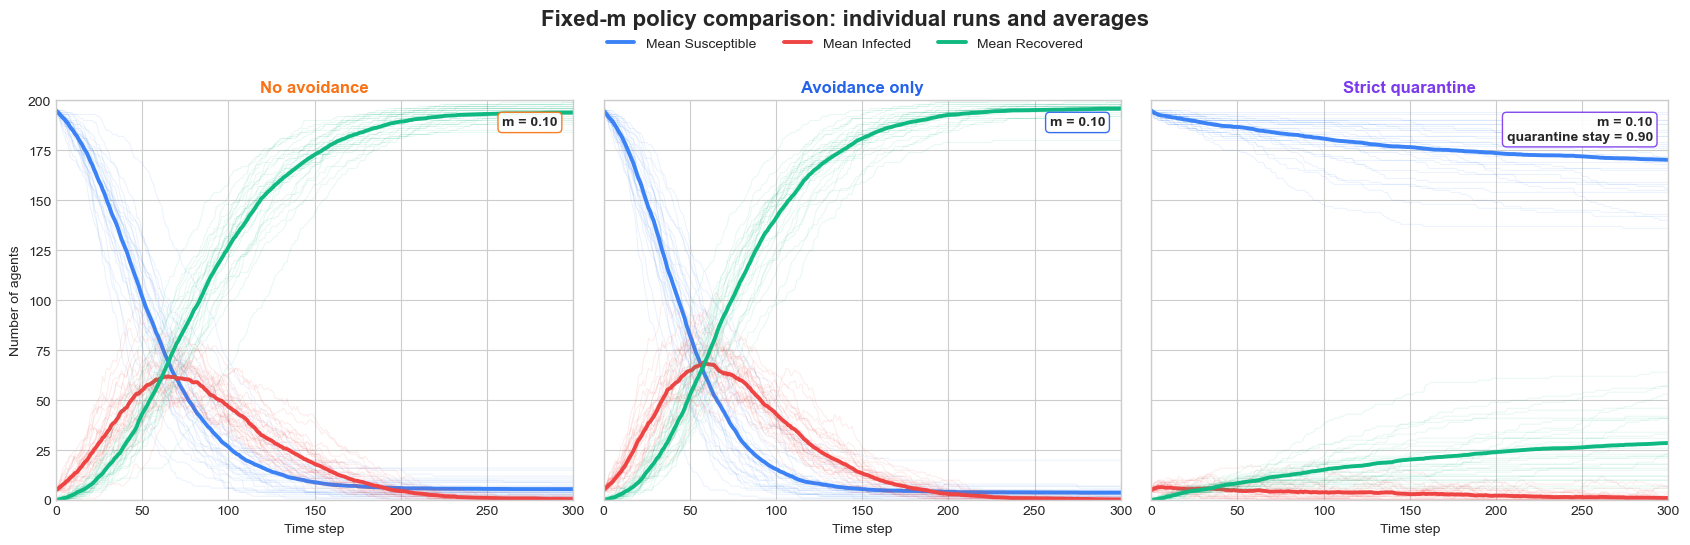

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharex=True, sharey=True)
times = np.arange(CONFIG.time_steps + 1)

for ax, (policy, histories) in zip(axes, policy_histories.items()):
    for state in (SUSCEPTIBLE, INFECTED, RECOVERED):
        color = STATE_COLORS[state]
        ax.plot(times, histories[:, :, state].T, color=color, alpha=0.10, lw=0.7)
        ax.plot(times, histories[:, :, state].mean(axis=0), color=color, lw=2.8,
                label=f"Mean {STATE_NAMES[state]}")

    policy_text = f"m = {FIXED_M:.2f}"
    if policy == "Strict quarantine":
        policy_text += f"\nquarantine stay = {QUARANTINE_STAY_PROBABILITY:.2f}"
    ax.text(0.97, 0.96, policy_text, transform=ax.transAxes, ha="right", va="top",
            fontsize=10, weight="bold",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor=POLICY_COLORS[policy], alpha=0.92))
    ax.set_title(policy, color=POLICY_COLORS[policy], weight="bold")
    ax.set_xlabel("Time step")
    ax.set_xlim(0, CONFIG.time_steps)
    ax.set_ylim(0, N_AGENTS)

axes[0].set_ylabel("Number of agents")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.01))
fig.suptitle("Fixed-m policy comparison: individual runs and averages",
             fontsize=16, weight="bold", y=1.04)
fig.tight_layout()
plt.show()


### Peak outcomes across policies

Points are individual runs; bars and error bars show the mean and its 95% confidence interval. Peak timing is the first time step at which a run reaches its maximum infected count.

In [12]:
policy_metric_rows = []
for policy, histories in policy_histories.items():
    infected = histories[:, :, INFECTED]
    for run_id in range(CONFIG.n_runs):
        policy_metric_rows.append({
            "policy": policy,
            "run": run_id + 1,
            "peak_infected": infected[run_id].max(),
            "time_to_peak": infected[run_id].argmax(),
        })
policy_metrics = pd.DataFrame(policy_metric_rows)

policy_summary = (
    policy_metrics.groupby("policy", sort=False)
    .agg(
        n=("run", "count"),
        mean_peak=("peak_infected", "mean"),
        sd_peak=("peak_infected", "std"),
        median_peak=("peak_infected", "median"),
        mean_peak_time=("time_to_peak", "mean"),
        sd_peak_time=("time_to_peak", "std"),
        median_peak_time=("time_to_peak", "median"),
    )
    .reset_index()
)
policy_summary["peak_95ci"] = 1.96 * policy_summary["sd_peak"] / np.sqrt(policy_summary["n"])
policy_summary["peak_time_95ci"] = 1.96 * policy_summary["sd_peak_time"] / np.sqrt(policy_summary["n"])
display(policy_summary.round(2).style.hide(axis="index"))


policy,n,mean_peak,sd_peak,median_peak,mean_peak_time,sd_peak_time,median_peak_time,peak_95ci,peak_time_95ci
No avoidance,30,71.170000,10.410000,69.500000,66.730000,15.680000,62.500000,3.730000,5.610000
Avoidance only,30,75.870000,12.300000,74.500000,59.670000,16.360000,58.000000,4.400000,5.850000
Strict quarantine,30,10.000000,3.560000,9.500000,71.370000,83.230000,36.000000,1.270000,29.780000


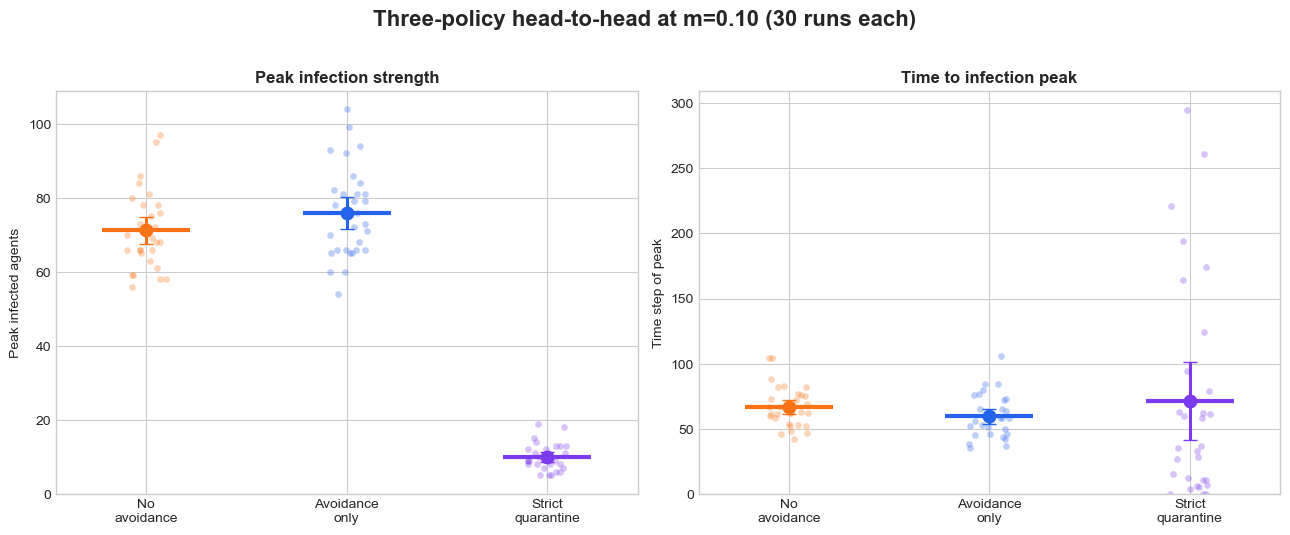

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
policy_order = list(policy_histories)
policy_plot_rng = np.random.default_rng(CONFIG.seed + 3_000)
plot_specs = [
    ("peak_infected", "mean_peak", "peak_95ci",
     "Peak infection strength", "Peak infected agents"),
    ("time_to_peak", "mean_peak_time", "peak_time_95ci",
     "Time to infection peak", "Time step of peak"),
]

for ax, (raw_col, mean_col, ci_col, title, ylabel) in zip(axes, plot_specs):
    for x, policy in enumerate(policy_order):
        group = policy_metrics[policy_metrics["policy"] == policy]
        row = policy_summary[policy_summary["policy"] == policy].iloc[0]
        color = POLICY_COLORS[policy]
        jitter_x = x + policy_plot_rng.uniform(-0.10, 0.10, size=len(group))
        ax.scatter(jitter_x, group[raw_col], color=color, alpha=0.30, s=24,
                   edgecolors="white", linewidths=0.3, zorder=2)
        ax.errorbar(x, row[mean_col], yerr=row[ci_col], fmt="o", color=color,
                    markersize=9, capsize=5, elinewidth=2.2, zorder=4)
        ax.hlines(row[mean_col], x - 0.22, x + 0.22, color=color, lw=3, zorder=3)

    ax.set_title(title, weight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(policy_order)),
                  [label.replace(" ", "\n") for label in policy_order])
    ax.set_xlim(-0.45, len(policy_order) - 0.55)
    ax.set_ylim(bottom=0)

fig.suptitle(
    f"Three-policy head-to-head at m={FIXED_M:.2f} ({CONFIG.n_runs} runs each)",
    fontsize=16, weight="bold", y=1.02
)
fig.tight_layout()
plt.show()


### Matched spatial snapshots

These rows use the same initial population and random seed. They show how the strict policy tends to keep active infection spatially localized by sharply reducing movement among infected agents and their susceptible cellmates.

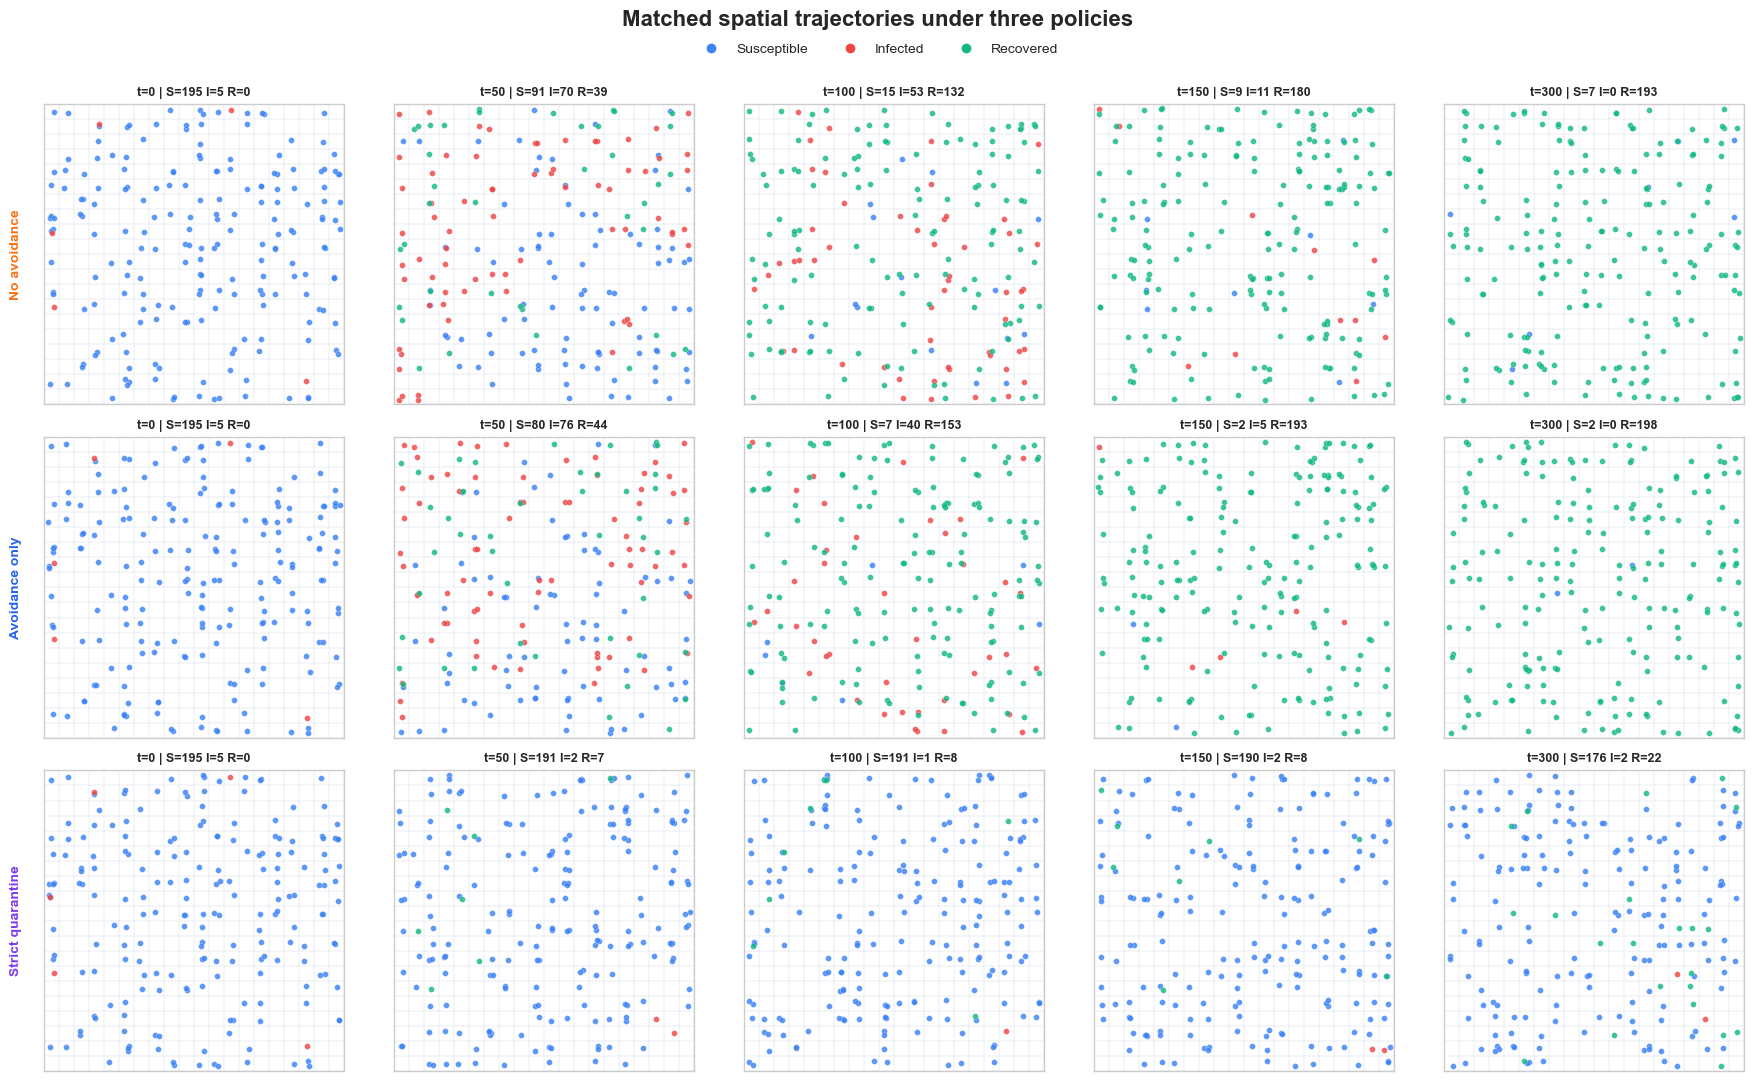

In [14]:
policy_snapshot_times = sorted(CONFIG.snapshot_times)
fig, axes = plt.subplots(
    len(policy_histories), len(policy_snapshot_times),
    figsize=(3.6 * len(policy_snapshot_times), 3.5 * len(policy_histories)),
    squeeze=False
)
quarantine_plot_rng = np.random.default_rng(CONFIG.seed + 4_000)

for row, policy in enumerate(policy_histories):
    snapshots = policy_snapshots[policy]
    for col, step in enumerate(policy_snapshot_times):
        ax = axes[row, col]
        positions, states = snapshots[step]
        jitter = quarantine_plot_rng.uniform(-0.20, 0.20, size=positions.shape)
        for state in (SUSCEPTIBLE, INFECTED, RECOVERED):
            mask = states == state
            ax.scatter(positions[mask, 1] + jitter[mask, 1],
                       positions[mask, 0] + jitter[mask, 0],
                       s=18, color=STATE_COLORS[state], alpha=0.82,
                       edgecolors="white", linewidths=0.2)

        counts = state_counts(states)
        ax.set_title(f"t={step} | S={counts[0]} I={counts[1]} R={counts[2]}",
                     fontsize=9, weight="bold")
        ax.set_xlim(-0.5, CONFIG.grid_size - 0.5)
        ax.set_ylim(CONFIG.grid_size - 0.5, -0.5)
        ax.set_aspect("equal")
        ax.set_xticks(np.arange(-0.5, CONFIG.grid_size, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, CONFIG.grid_size, 1), minor=True)
        ax.grid(which="minor", color="#CBD5E1", linewidth=0.28)
        ax.grid(which="major", visible=False)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(policy, fontsize=10, weight="bold", labelpad=12,
                          color=POLICY_COLORS[policy])

fig.legend(handles=legend_handles, loc="upper center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 1.005))
fig.suptitle("Matched spatial trajectories under three policies",
             fontsize=16, weight="bold", y=1.025)
fig.tight_layout()
plt.show()
